### Heat demand profiles at local authority level using National Grid's Future Energy Scenarios

In [1]:
import os
from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv())
src_path = os.environ.get('PROJECT_SRC')
os.chdir(src_path)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

import heat_demand as hdr
import heat_pattern
import FES_scaling_factor
import geopandas as gpd

In [3]:
weather_year = 2020
future_year = 2050
FES_year = '2022'
FES_scenario = 'LW'


In [4]:
grid_id = '-0.25_50.75'

LA_shapefile = gpd.read_file(r'data\LA_UK\new_version\UK_LAs_Boundaries_files\LAs_shapefile_2021\LAD_DEC_2021_GB_BFC.shp')
grid_squares =  gpd.read_file(r'data\LA_UK\new_version\data_call\UK_Atlite_Grid_sq.gpkg')

In [5]:
grid_sq_heat_pattern_total = heat_pattern.grid_sq_heat_pattern_totals(grid_squares, LA_shapefile, weather_year, future_year, FES_year, FES_scenario)
# grid_sq_heat_pattern_total[grid_id].sum(axis=1)
if grid_id in grid_sq_heat_pattern_total:
    total_profile = grid_sq_heat_pattern_total[grid_id].sum(axis=1)
    print(total_profile)
else:
    print(f"Grid ID {grid_id} not found.")

Sample FES LAs: ['Aberdeen City', 'Aberdeenshire', 'Adur', 'Allerdale', 'Amber Valley', 'Angus', 'Argyll And Bute', 'Arun', 'Ashfield', 'Ashford']
Sample Grid LAs: ['Isles Of Scilly' 'Cornwall' 'Plymouth' 'South Hams' 'Torbay'
 'West Devon' 'Teignbridge' 'East Devon' 'Dorset' 'Isle Of Wight']
Sample FES LAs: ['Aberdeen City', 'Aberdeenshire', 'Adur', 'Allerdale', 'Amber Valley', 'Angus', 'Argyll And Bute', 'Arun', 'Ashfield', 'Ashford']
Sample Grid LAs: ['Isles Of Scilly' 'Cornwall' 'Plymouth' 'South Hams' 'Torbay'
 'West Devon' 'Teignbridge' 'East Devon' 'Dorset' 'Isle Of Wight']
ASHP                                   26672.147192
GSHP                                   31128.531456
Gas boiler                                 0.100449
BioLPG boiler                           4601.673755
Biomass boiler                          1936.257628
Community                                  1.836929
DH                                     23074.530551
Electric resistive                      1834.825

In [8]:
air_temp_daily = pd.read_csv('data/LA_UK/new_version/air_temp_new/average_day_air_temp_' + str(weather_year) + '.csv')
normalised_profiles = {'daytime': pd.read_excel('data/normalised_half_hourly_profiles.xlsx', sheet_name='Total heat daytime HPs', usecols="B:I"),
                           'bi-modal': pd.read_excel('data/normalised_half_hourly_profiles.xlsx', sheet_name='Total heat bimodal HPs', usecols="B:I"),
                           'continuous': pd.read_excel('data/normalised_half_hourly_profiles.xlsx', sheet_name='Total heat continuous HPs', usecols="B:I")}
FES_scaling = FES_scaling_factor.FES_scaling_factor_calc(future_year, FES_year, FES_scenario)
hdr.heat_demand_for_grid_sq_half_hourly(grid_id, air_temp_daily, weather_year, future_year, FES_year, FES_scenario, FES_scaling, normalised_profiles, grid_sq_heat_pattern_total)

File not found. Generating: data\LA_UK\new_version\outputs\heat_demand_profiles\(-0.25_50.75)_LW_2022_2020_2050.csv
Saved new file: data\LA_UK\new_version\outputs\heat_demand_profiles\(-0.25_50.75)_LW_2022_2020_2050.csv


,ASHP,GSHP,Gas boiler,BioLPG boiler,Biomass boiler,Community,DH,Electric resistive,Hybrid (ASHP + BioLPG boiler),Hybrid (ASHP + Electric resistive),Hybrid (ASHP + Hydrogen boiler),Hydrogen boiler,Oil boiler,Total,Electric storage
2050-01-01 00:00:00,7221.382124,9599.195579,0.015611,715.178788,300.927545,0.285490,3586.176614,285.163287,186.727178,3219.799166,1646.579880,2078.060139,0.000002,22106.785018,2732.449573
2050-01-01 00:30:00,7348.682778,9828.512742,0.015244,698.326679,293.836641,0.278763,3501.673772,278.443845,182.327234,3143.929456,1607.780710,2029.093787,0.000002,21585.871980,2821.247842
2050-01-01 01:00:00,7659.187906,10265.326244,0.015624,715.776476,301.179035,0.285729,3589.173645,285.401604,186.883229,3222.490010,1647.955957,2079.796811,0.000002,22125.260053,2954.445244
2050-01-01 01:30:00,7903.493871,10598.197785,0.016014,733.616465,308.685611,0.292850,3678.630089,292.514944,191.541101,3302.807243,1689.029556,2131.633597,0.000002,22676.709295,3051.489066
2050-01-01 02:00:00,8491.845941,11329.424295,0.017681,809.972383,340.814079,0.323331,4061.507504,322.960344,211.476990,3646.568444,1864.826321,2353.497264,0.000002,25036.935689,3237.172588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2050-12-31 21:30:00,15422.410690,18402.928305,0.055501,2542.553697,1069.836597,1.014955,12749.324718,1013.792610,663.839427,11446.805197,5853.805831,7387.774320,0.000008,78592.498654,4412.576989
2050-12-31 22:00:00,13589.510373,16630.574546,0.044673,2046.532381,861.124483,0.816949,10262.086463,816.013997,534.332425,9213.672666,4711.799480,5946.509366,0.000006,63260.057643,4172.100116
2050-12-31 22:30:00,11796.650781,14908.225551,0.033805,1548.643905,651.626720,0.618199,7765.485559,617.490891,404.337924,6972.134008,3565.494302,4499.819093,0.000005,47869.901100,3941.823976
2050-12-31 23:00:00,10455.915004,13623.458154,0.025571,1171.446272,492.912340,0.467626,5874.074135,467.090852,305.854788,5273.956372,2697.059663,3403.814320,0.000004,36210.401238,3770.581871


In [9]:
file_name = f"({grid_id})_{FES_scenario}_{FES_year}_{weather_year}_{future_year}.csv"

folder = r"data\LA_UK\new_version\outputs\heat_demand_profiles"
file_path = os.path.join(folder, file_name)

hd_df = pd.read_csv(file_path, index_col=0)
hd_df.index = pd.to_datetime(hd_df.index)


In [10]:
hd_df.columns

Index(['ASHP', 'GSHP', 'Gas boiler', 'BioLPG boiler', 'Biomass boiler',
       'Community', 'DH', 'Electric resistive',
       'Hybrid (ASHP + BioLPG boiler)', 'Hybrid (ASHP + Electric resistive)',
       'Hybrid (ASHP + Hydrogen boiler)', 'Hydrogen boiler', 'Oil boiler',
       'Total', 'Electric storage'],
      dtype='object')

<Axes: >

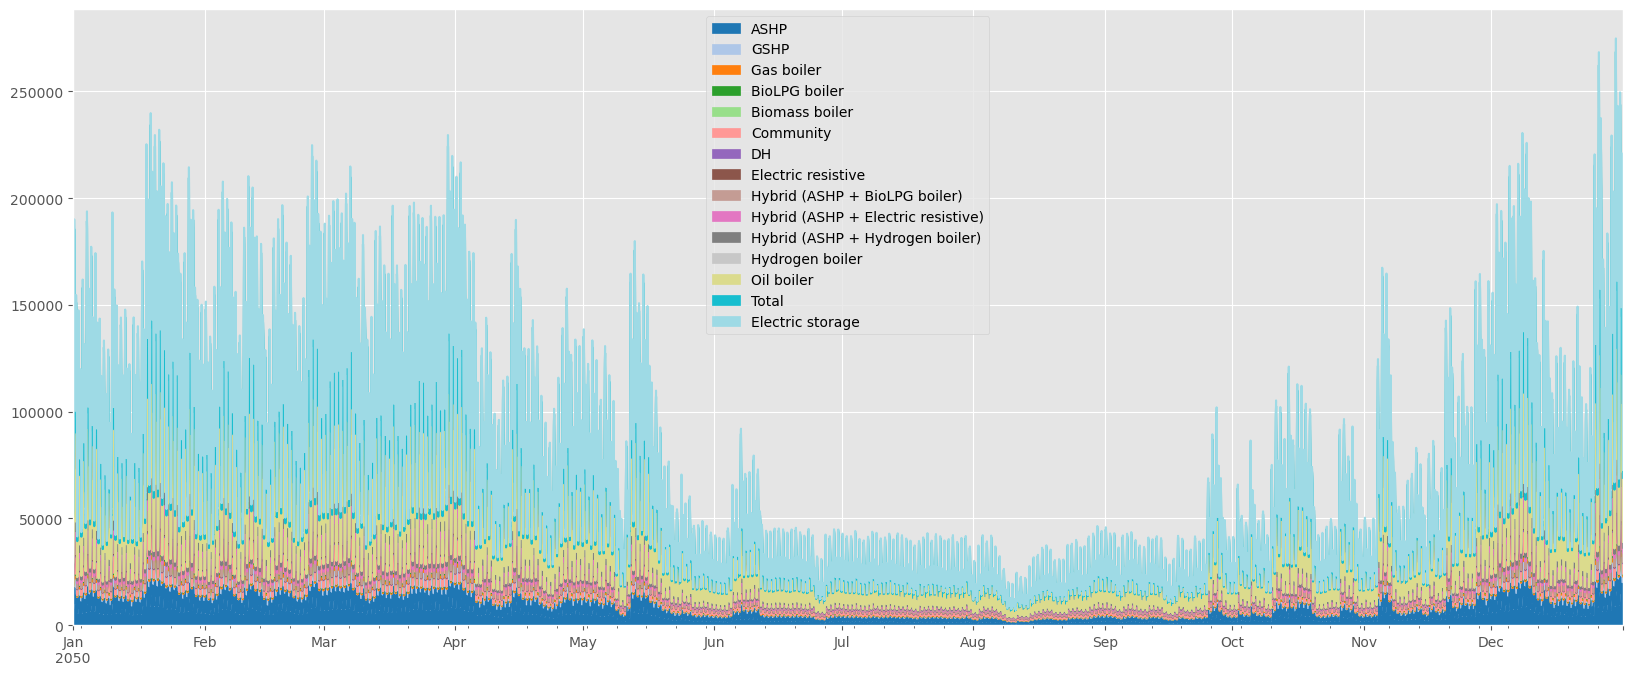

In [11]:
plt.style.use('ggplot')
hd_df.plot.area(figsize=(20,8), cmap='tab20')

<Axes: >

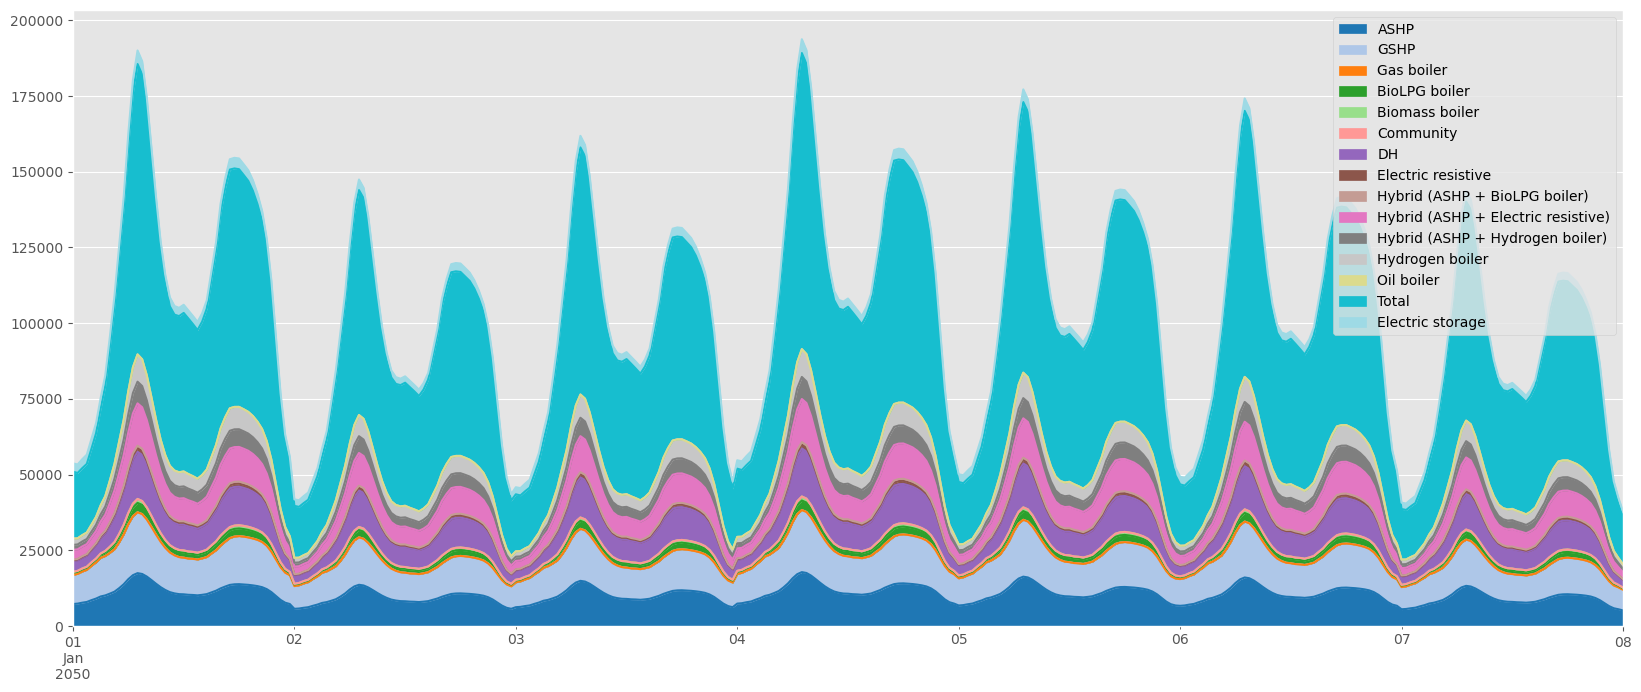

In [12]:
plt.style.use('ggplot')
hd_df['2050-01-01 00:00:00': '2050-01-08 00:00:00'].plot.area(figsize=(20,8), stacked=True, cmap='tab20')

In [13]:
hd_df.sum().sum()

1166121321.5340009